# Medium-world learning order — 600-update analysis

This is the **600-update learning-order pilot**, comparing `mixed`, `staged` and `reverse` training. We investigate whether the model begins learning shape and binding in such a short budget. This notebook reads the saved experiment; it does not train anything.

**Figures and tables:** exported to `outputs/medium_world/experiments/learning_order/`.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

source = PROJECT_ROOT / 'outputs/medium_world/experiments/learning_order/schedule_comparison.json'
report = json.loads(source.read_text(encoding='utf-8'))
runs = report['runs']
SCHEDULES = ('mixed', 'staged', 'reverse')
TASKS = ('color', 'shape', 'conjunction', 'pair')
print('Updates:', runs[0]['steps_run'], '| Runs:', len(runs), '| LR:', report['config']['lr'])
OUTPUT_DIR = source.parent

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=300,
                bbox_inches='tight', facecolor='white')

Updates: 600 | Runs: 15 | LR: 0.002


## 1. Experimental exposure

The pilot used **600 updates**, three presentations of each training example, and a learning rate of `0.002`. Compare the same seeds under the same exposure budget. Later studies have longer budgets and different optimization settings; their scores are not directly attributable to curriculum order.

In [2]:
exposure = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'updates': r['steps_run'],
    'total_presentations': r['exposure_plan']['total_presentations'],
    **r['exposure_plan']['counts_by_template']
} for r in runs])
display(exposure.sort_values(['seed', 'schedule']).reset_index(drop=True))

,seed,schedule,updates,total_presentations,color,shape,conjunction,pair
0,42,mixed,600,30000,7500,7500,7500,7500
1,42,reverse,600,30000,7500,7500,7500,7500
2,42,staged,600,30000,7500,7500,7500,7500
3,43,mixed,600,30000,7500,7500,7500,7500
4,43,reverse,600,30000,7500,7500,7500,7500
5,43,staged,600,30000,7500,7500,7500,7500
6,44,mixed,600,30000,7500,7500,7500,7500
7,44,reverse,600,30000,7500,7500,7500,7500
8,44,staged,600,30000,7500,7500,7500,7500
9,45,mixed,600,30000,7500,7500,7500,7500


## 2. Final performance and visual grounding

`pair` asks whether a color and shape occur **on the same object**, rather than merely somewhere in the image. Compare binding accuracy with the constant-image control to see whether the model relies on the actual visual input.

In [3]:
rows = []
for r in runs:
    f = r['final']
    rows.append({
        'seed': r['seed'], 'schedule': r['schedule'],
        'overall_id': 100 * f['id_dev']['accuracy'],
        'ood_pair': 100 * f['ood_dev']['by_template']['pair'],
        'ood_bce': f['ood_dev']['loss'],
        'constant_image': 100 * f['id_dev_constant_image']['accuracy'],
        **{t: 100 * f['id_dev']['by_template'][t] for t in TASKS}
    })
final = pd.DataFrame(rows)
display(final.sort_values(['seed', 'schedule']).round(2))
final.to_csv(OUTPUT_DIR / 'pilot_final_metrics.csv', index=False)
display(final.groupby('schedule')[['overall_id', 'shape', 'pair', 'ood_pair', 'constant_image']]
        .agg(['mean', 'std']).reindex(SCHEDULES).round(2))

,seed,schedule,overall_id,ood_pair,ood_bce,constant_image,color,shape,conjunction,pair
0,42,mixed,68.95,49.50,0.69,50.1,92.58,53.52,76.95,52.73
2,42,reverse,68.55,52.00,0.70,50.2,94.92,54.30,75.00,50.00
1,42,staged,70.51,51.50,0.71,50.0,99.22,55.47,77.34,50.00
3,43,mixed,70.61,56.50,0.68,50.0,94.53,53.91,76.56,57.42
5,43,reverse,70.80,51.50,0.70,50.2,99.22,51.17,80.08,52.73
4,43,staged,71.97,54.00,0.69,50.2,99.61,53.12,81.64,53.52
6,44,mixed,53.03,50.50,0.69,50.2,57.03,50.78,55.08,49.22
8,44,reverse,60.64,49.75,0.70,50.1,71.48,53.91,65.62,51.56
7,44,staged,70.51,47.25,0.70,50.0,99.61,51.56,78.91,51.95
9,45,mixed,71.39,51.00,0.70,50.0,100.00,52.73,80.08,52.73


overall_id        shape         pair       ood_pair        \
               mean   std   mean   std   mean   std     mean   std   
schedule                                                             
mixed         64.63  8.13  52.50  1.31  52.66  3.03     51.5  2.85   
staged        69.02  2.80  53.05  2.32  51.33  1.58     50.8  2.68   
reverse       64.24  5.28  53.67  2.74  51.41  1.37     51.0  1.05   

         constant_image        
                   mean   std  
schedule                       
mixed             50.06  0.09  
staged            50.06  0.09  
reverse           50.14  0.05

## Final binding and OOD performance — report figure

Mean ± seed standard deviation across the three short-budget schedules. The two splits measure different generalization regimes; the dotted 50% line is chance on the balanced original splits.

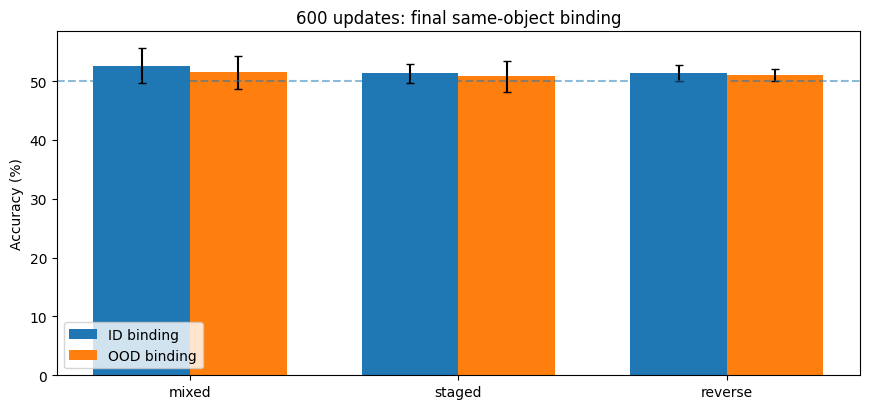

In [ ]:
means = final.groupby('schedule')[['pair', 'ood_pair']].mean().reindex(SCHEDULES)
stds = final.groupby('schedule')[['pair', 'ood_pair']].std().reindex(SCHEDULES)
x = np.arange(len(SCHEDULES))
width = 0.36
fig, ax = plt.subplots(figsize=(8.8, 4.2))
ax.bar(x - width/2, means['pair'], width, yerr=stds['pair'], capsize=3, label='ID binding')
ax.bar(x + width/2, means['ood_pair'], width, yerr=stds['ood_pair'], capsize=3, label='OOD binding')
ax.axhline(50, linestyle='--', alpha=.5)
ax.set(xticks=x, xticklabels=SCHEDULES, ylabel='Accuracy (%)',
       title='600 updates: final same-object binding')
ax.legend()
plt.tight_layout()
save_figure(fig, 'final_binding_id_ood')
plt.show()

## 3. Paired comparisons

For each seed \(s\), compute the difference between two schedules trained from matching seeds:

$$\overline{\Delta}=\frac{1}{S}\sum_{s=1}^{S}(A_{s,\mathrm{staged}}-A_{s,\mathrm{mixed}}).$$

Comparing paired differences is more informative than selecting the best seed. With five seeds, small differences remain exploratory.

In [5]:
for first, second in (('staged', 'mixed'), ('reverse', 'mixed'), ('staged', 'reverse')):
    print(f'\n{first} − {second}')
    for metric in ('pair', 'ood_pair', 'overall_id', 'shape'):
        p = final.pivot(index='seed', columns='schedule', values=metric)
        difference = p[first] - p[second]
        print(f'{metric:12s}: {difference.mean():+6.2f} pp | '
              f'wins {(difference > 0).sum()}/{len(difference)}')


staged − mixed
pair        :  -1.33 pp | wins 2/5
ood_pair    :  -0.70 pp | wins 2/5
overall_id  :  +4.39 pp | wins 4/5
shape       :  +0.55 pp | wins 3/5

reverse − mixed
pair        :  -1.25 pp | wins 1/5
ood_pair    :  -0.50 pp | wins 2/5
overall_id  :  -0.39 pp | wins 2/5
shape       :  +1.17 pp | wins 3/5

staged − reverse
pair        :  -0.08 pp | wins 3/5
ood_pair    :  -0.20 pp | wins 2/5
overall_id  :  +4.79 pp | wins 5/5
shape       :  -0.62 pp | wins 2/5


## 4. Learning trajectories

A curriculum may change **when** a skill emerges without changing its final accuracy. The saved pilot records evaluations from step 100 onward, so these plots show only the observed part of the trajectory.

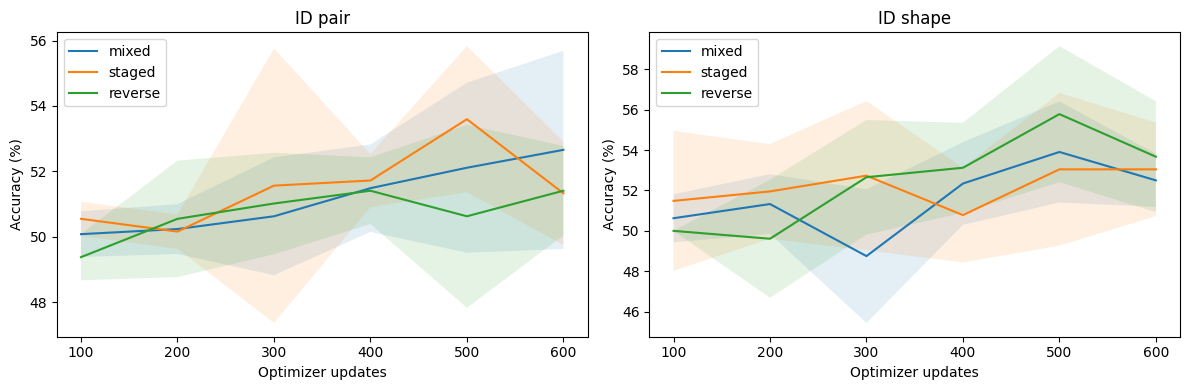

In [6]:
history = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'],
    'step': h['step'], 'phase': h['phase'],
    **{t: 100 * h['id_dev']['by_template'][t] for t in TASKS}
} for r in runs for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, ('pair', 'shape')):
    for schedule in SCHEDULES:
        curve = history[history.schedule == schedule].groupby('step')[task].agg(['mean', 'std'])
        ax.plot(curve.index, curve['mean'], label=schedule)
        ax.fill_between(curve.index, curve['mean'] - curve['std'],
                        curve['mean'] + curve['std'], alpha=.12)
    ax.set(title=f'ID {task}', xlabel='Optimizer updates', ylabel='Accuracy (%)')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'id_shape_binding_learning_curves')
plt.show()

## 5. Interference when the stage changes

We compare the last recorded evaluation of each phase with the first evaluation of the next one. A drop in an earlier task is consistent with **interference**, but it also includes further optimization updates and cannot isolate forgetting causally.

In [7]:
changes = []
for r in runs:
    for before, after in zip(r['history'], r['history'][1:]):
        if before['phase'] == after['phase']:
            continue
        changes.append({
            'seed': r['seed'], 'schedule': r['schedule'],
            'transition': before['phase'] + ' → ' + after['phase'],
            'updates_between': after['step'] - before['step'],
            **{t: 100 * (after['id_dev']['by_template'][t] -
                         before['id_dev']['by_template'][t]) for t in TASKS}
        })
changes = pd.DataFrame(changes)
changes.to_csv(OUTPUT_DIR / 'pilot_transition_deltas.csv', index=False)
display(changes.groupby(['schedule', 'transition'])
        [list(TASKS)].mean().round(2))

color  shape  conjunction  pair
schedule transition                                                
mixed    mixed → common_mixed        2.03   1.56         3.28  0.62
reverse  attributes → common_mixed   5.94   2.66         3.83 -0.78
         binding → conjunction       7.03  -0.39         5.94  1.17
         conjunction → attributes   11.95   3.05         5.00  0.47
staged   attributes → conjunction    4.38   0.78         9.06  1.41
         binding → common_mixed     24.53   2.27        14.84  1.88
         conjunction → binding     -13.36  -1.95       -10.23  0.16

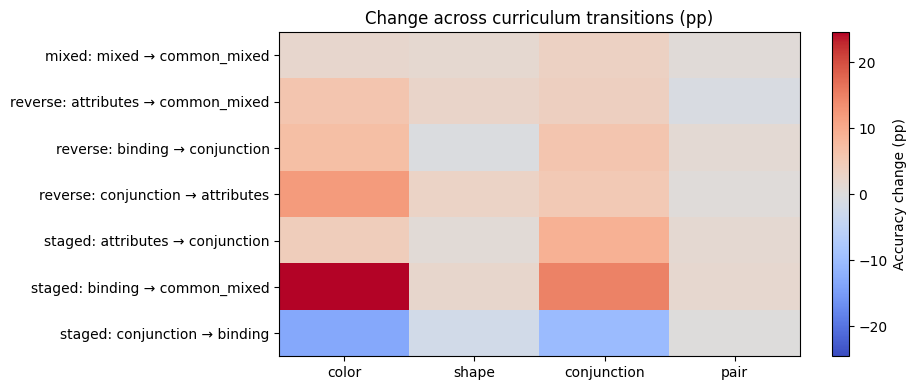

In [8]:
transition_mean = changes.groupby(['schedule', 'transition'])[list(TASKS)].mean()
fig, ax = plt.subplots(figsize=(9.5, 4))
values = transition_mean.to_numpy()
bound = np.max(np.abs(values))
im = ax.imshow(values, cmap='coolwarm', vmin=-bound, vmax=bound, aspect='auto')
ax.set(xticks=np.arange(len(TASKS)), xticklabels=TASKS,
       yticks=np.arange(len(transition_mean)),
       yticklabels=[f'{s}: {t}' for s,t in transition_mean.index],
       title='Change across curriculum transitions (pp)')
fig.colorbar(im, ax=ax, label='Accuracy change (pp)')
plt.tight_layout()
save_figure(fig, 'transition_accuracy_changes')
plt.show()

## 6. What could each schedule demonstrate at each checkpoint?

This pilot saved only six evaluations (100–600 updates), so it cannot measure a continuous learning trajectory within every stage. Instead, compare **all four skills at each recorded checkpoint**. A task improving before it is taught is a *candidate* for forward transfer, but could also be a question-prior shortcut.

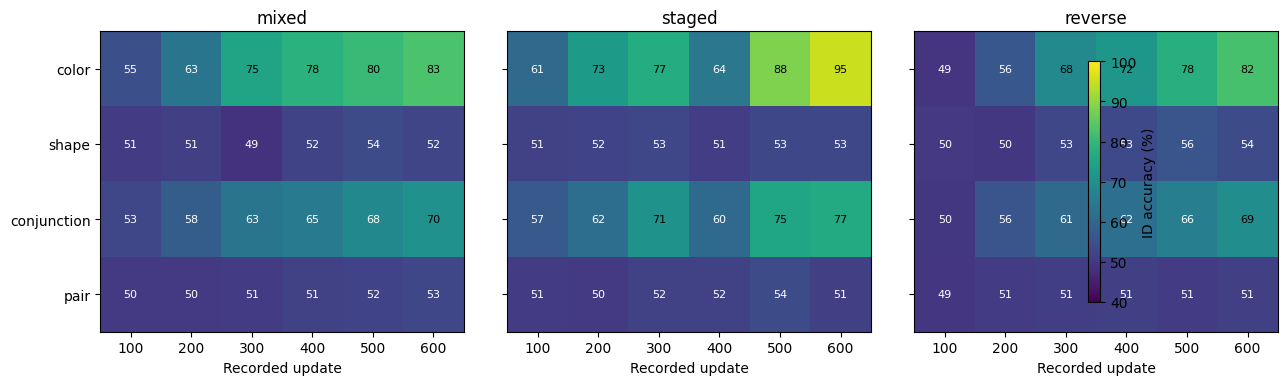

In [9]:
checkpoint_mean = history.groupby(['schedule', 'step'])[list(TASKS)].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, schedule in zip(axes, SCHEDULES):
    scores = checkpoint_mean.loc[schedule].T
    image = ax.imshow(scores, vmin=40, vmax=100, cmap='viridis', aspect='auto')
    ax.set(xticks=range(len(scores.columns)), xticklabels=scores.columns,
           yticks=range(len(TASKS)), yticklabels=TASKS,
           title=schedule, xlabel='Recorded update')
    for i in range(len(TASKS)):
        for j in range(scores.shape[1]):
            ax.text(j, i, f'{scores.iloc[i, j]:.0f}', ha='center', va='center',
                    color='white' if scores.iloc[i, j] < 68 else 'black', fontsize=8)
fig.colorbar(image, ax=axes, label='ID accuracy (%)', shrink=.8)
fig.subplots_adjust(wspace=.12, right=.91)
save_figure(fig, 'checkpoint_skill_matrix')
plt.show()
checkpoint_mean.to_csv(OUTPUT_DIR / 'pilot_checkpoint_skill_matrix.csv')

## 7. Did the image actually matter?

The saved constant-image control removes visual information during evaluation. Its final accuracy must be interpreted alongside the original ID accuracy: a large gap indicates visual dependence, **not** proof that the model performs true same-object binding.

In [10]:
grounding = final.copy()
grounding['visual_gain'] = grounding['overall_id'] - grounding['constant_image']
display(grounding.groupby('schedule')[['overall_id', 'constant_image', 'visual_gain']]
        .agg(['mean', 'std']).reindex(SCHEDULES).round(2))
grounding[['seed', 'schedule', 'visual_gain']].to_csv(OUTPUT_DIR / 'pilot_visual_gain.csv', index=False)

overall_id       constant_image       visual_gain      
               mean   std           mean   std        mean   std
schedule                                                        
mixed         64.63  8.13          50.06  0.09       14.57  8.19
staged        69.02  2.80          50.06  0.09       18.96  2.77
reverse       64.24  5.28          50.14  0.05       14.10  5.23

## Interpretation

This 600-update pilot is informative about **initial learning** and visual dependence, but it is too brief and sparsely logged to establish robust transfer or sustained forgetting. Compare more detailed phase dynamics in the later 3,000- and 9,000-update experiments.